In [1]:
%cd /Users/bernardomb/Desktop/CCP/computoparalelo2026b


/Users/bernardomb/Desktop/CCP/computoparalelo2026b


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/IPython/core/magics/osm.py:417: UserWarning: This is now an optional IPython functionality, setting dhist requires you to install the `pickleshare` library.
  self.shell.db['dhist'] = compress_dhist(dhist)[-100:]


In [2]:
%ls

DBSCAN_noise.ipynb       emptyfloydwarshall.cpp   mpi_hello_world.cpp
dbscan/                  emptyfloydwarshall.dSYM/ mpi_hello_world.dSYM/
emptyfloydwarshall*      mpi_hello_world*


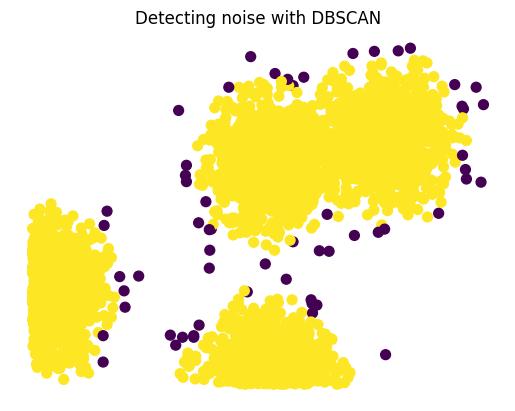

In [3]:
from sklearn.cluster import DBSCAN
from sklearn.datasets import make_blobs
import matplotlib.pyplot as plt
import numpy as np

n_points = 4000

points, y_true = make_blobs(n_samples=n_points,
                            centers=4,
                            cluster_std=0.06,
                            random_state=11,
                            center_box=(0, 1.0))

points = np.round(np.abs(points[:, ::-1]), 3)

np.savetxt(str(n_points)+"_data.csv", points, delimiter=",",  fmt="%.3f")

clusters = DBSCAN(eps=0.03, min_samples=10).fit_predict(points)

plt.figure()
plt.title("Detecting noise with DBSCAN")
plt.scatter(points[:, 0], points[:, 1], c=np.where(clusters==-1, 0, 1), s=50)
plt.xticks([])
plt.yticks([])
plt.box(False)
plt.show()

In [4]:
print(n_points)

4000


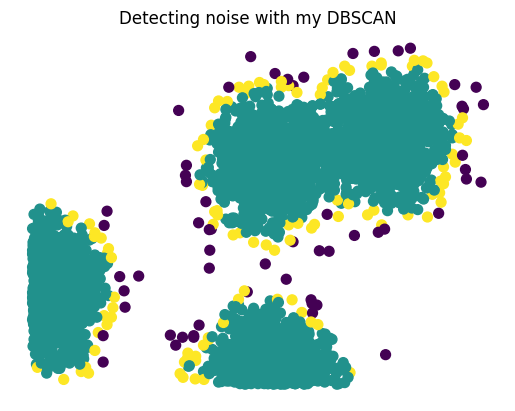

In [8]:
result = np.loadtxt("dbscan/data/"+str(n_points)+"_results.csv", delimiter=",")

plt.figure()
plt.title("Detecting noise with my DBSCAN")
plt.scatter(result.T[0], result.T[1], c=result.T[2], s=50)
plt.xticks([])
plt.yticks([])
plt.box(False)
plt.show()

/Users/bernardomb/Desktop/CCP/computoparalelo2026b
version     n  threads  k  seconds   speedup
     p1  4000        1  0 0.009116  0.878401
     p1  4000        4  0 0.001762  4.545717
     p1  4000        8  0 0.001382  5.794182
     p1  4000       16  0 0.001332  6.011998
     p1 20000        1  0 0.135051  1.004843
     p1 20000        4  0 0.037491  3.619659
     p1 20000        8  0 0.028677  4.732190
     p1 20000       16  0 0.027823  4.877448
     p2  4000        1  2 0.006230  1.285319
     p2  4000        1  4 0.002931  2.731566
     p2  4000        1  8 0.001817  4.407321
     p2  4000        1 16 0.001495  5.354470
     p2  4000        1 32 0.001282  6.248560
     p2  4000        1 64 0.001339  5.978289
     p2  4000        4  2 0.002321  3.450205
     p2  4000        4  4 0.001309  6.117101
     p2  4000        4  8 0.000679 11.784575
     p2  4000        4 16 0.000507 15.790316
     p2  4000        4 32 0.000477 16.776231
     p2  4000        4 64 0.000463 17.281202
    

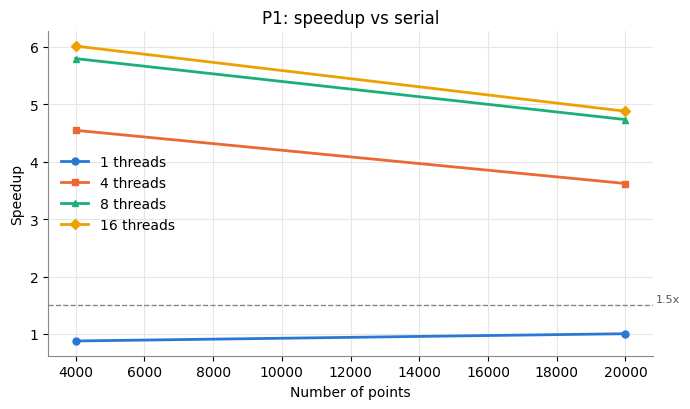

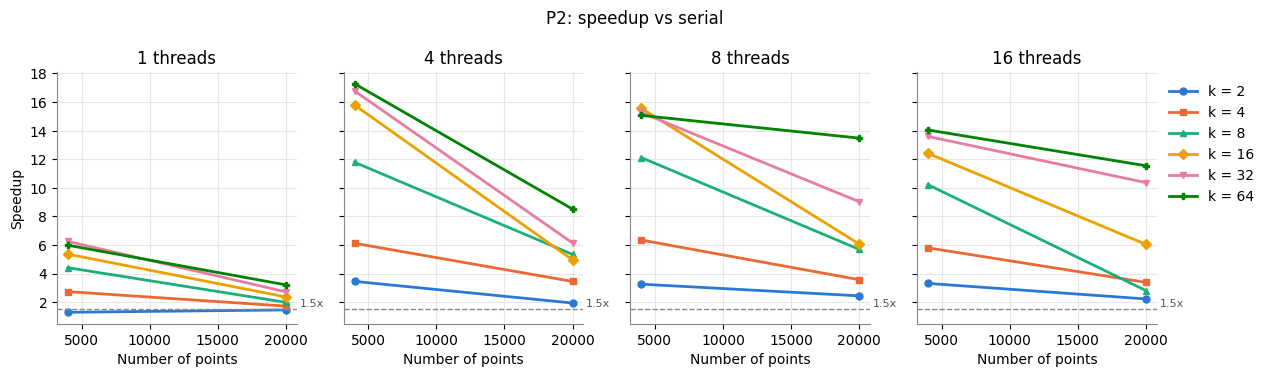

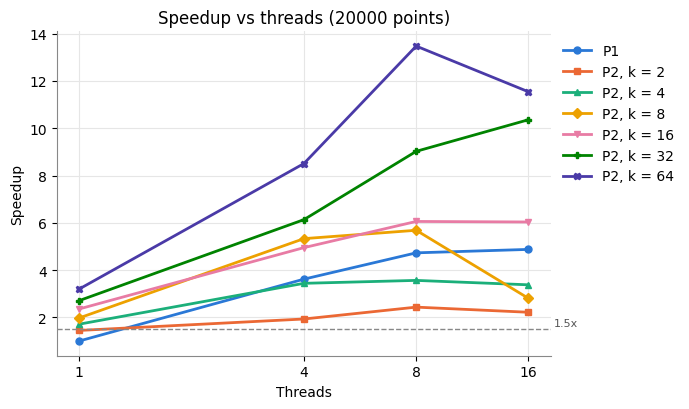

In [14]:
import os
import sys

import matplotlib.pyplot as plt
import pandas as pd

folder = os.getcwd()
print(os.getcwd())
path = os.path.join(folder, "dbscan", "results", "experiments_quick.csv")
out = os.path.dirname(os.path.abspath(path))

COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7"]
MARKERS = ["o", "s", "^", "D", "v", "P", "X"]
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#888888", "axes.grid": True, "grid.color": "#e6e6e6",
                     "grid.linewidth": 0.8, "axes.axisbelow": True})

df = pd.read_csv(path)
summary = df.groupby(["version", "n", "threads", "k"], as_index=False)["seconds"].mean()
serial = summary[summary.version == "serial"].set_index("n")["seconds"]
summary["speedup"] = summary["n"].map(serial) / summary["seconds"]
summary.to_csv(os.path.join(out, "summary.csv"), index=False)
print(summary.to_string(index=False))

p1 = summary[summary.version == "p1"]
p2 = summary[summary.version == "p2"]
threads = sorted(p1.threads.unique())
ks = sorted(p2.k.unique())

def reference_line(ax):
    """Dashed line at speedup 1.5, the minimum required by the project (NOTA 1)."""
    ax.axhline(1.5, color="#888888", linestyle="--", linewidth=1)
    ax.annotate("1.5x", xy=(1, 1.5), xycoords=("axes fraction", "data"),
                xytext=(2, 2), textcoords="offset points", color="#555555", fontsize=8)

def line(ax, x, y, i, label):
    ax.plot(x, y, color=COLORS[i], marker=MARKERS[i], linewidth=2, markersize=5, label=label)

fig, ax = plt.subplots(figsize=(7, 4.2))
for i, t in enumerate(threads):
    rows = p1[p1.threads == t]
    line(ax, rows.n, rows.speedup, i, f"{t} threads")
reference_line(ax)
ax.set_title("P1: speedup vs serial")
ax.set_xlabel("Number of points")
ax.set_ylabel("Speedup")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(os.path.join(out, "speedup_p1.png"), dpi=150)

fig, axes = plt.subplots(1, len(threads), figsize=(3.2 * len(threads), 3.8), sharey=True)
for ax, t in zip(axes, threads):
    for i, k in enumerate(ks):
        rows = p2[(p2.threads == t) & (p2.k == k)]
        line(ax, rows.n, rows.speedup, i, f"k = {k}")
    reference_line(ax)
    ax.set_title(f"{t} threads")
    ax.set_xlabel("Number of points")
axes[0].set_ylabel("Speedup")
axes[-1].legend(frameon=False, loc="upper left", bbox_to_anchor=(1, 1))
fig.suptitle("P2: speedup vs serial")
fig.tight_layout()
fig.savefig(os.path.join(out, "speedup_p2.png"), dpi=150)

n_max = summary.n.max()
fig, ax = plt.subplots(figsize=(7, 4.2))
rows = p1[p1.n == n_max]
line(ax, rows.threads, rows.speedup, 0, "P1")
for i, k in enumerate(ks, start=1):
    rows = p2[(p2.n == n_max) & (p2.k == k)]
    line(ax, rows.threads, rows.speedup, i, f"P2, k = {k}")
reference_line(ax)
ax.set_xscale("log", base=2)
ax.set_xticks(threads)
ax.set_xticklabels([str(t) for t in threads])
ax.set_title(f"Speedup vs threads ({n_max} points)")
ax.set_xlabel("Threads")
ax.set_ylabel("Speedup")
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1, 1))
fig.tight_layout()
fig.savefig(os.path.join(out, "speedup_threads.png"), dpi=150)

print("charts saved in", out)